## **Problem Set 1**. Vector representations, similarity & dimensionality reduction
### *Goal: establish the “everything is a vector/tensor” paradigm and the geometry it lives in.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy import linalg, stats
import seaborn as sns
import umap

##### 1. **[Theory]** Let $x, y \in \mathbb{R}^d$. Show that if $\Vert{}x\Vert{}_2 = \Vert{}y\Vert{}_2 = 1$ then $\Vert{}x - y\Vert{}_2^2 = 2(1 - \cos \theta)$, where $\cos \theta$ is the cosine similarity. Deduce that on the unit sphere Euclidean and cosine geometry induce the same ranking of neighbours.

$x, y \in \mathbb{R}^d$, $\|x\|_2 = \|y\|_2 = 1$

$$x = (x_1, x_2, \dots, x_d), \quad \|x\|_2 = \sqrt{x_1^2 + x_2^2 + \dots + x_d^2} = \sqrt{\sum_{i=1}^d x_i^2} = 1$$

$$y = (y_1, y_2, \dots, y_d), \quad \|y\|_2 = \sqrt{y_1^2 + y_2^2 + \dots + y_d^2} = \sqrt{\sum_{i=1}^d y_i^2} = 1$$

**Cosine similarity:**

$$\cos \theta = \frac{x \cdot y}{\|x\|_2 \|y\|_2} = \frac{\sum_{i=1}^d x_i y_i}{\sqrt{\sum x_i^2} \sqrt{\sum y_i^2}} = \frac{\sum_{i=1}^d x_i y_i}{1 \cdot 1} = \sum_{i=1}^d x_i y_i = x \cdot y \in [-1, 1]$$

$$\begin{aligned}
\|x - y\|_2^2 &= \left(\sqrt{\sum_{i=1}^d (x_i - y_i)^2}\right)^2 = \sum_{i=1}^d (x_i - y_i)^2 \\
&= \sum_{i=1}^d (x_i^2 - 2x_i y_i + y_i^2) \\
&= \sum_{i=1}^d x_i^2 - 2\sum_{i=1}^d x_i y_i + \sum_{i=1}^d y_i^2 \\
&= 1 - 2\sum_{i=1}^d x_i y_i + 1 \\
&= 2\left(1 - \sum_{i=1}^d x_i y_i\right) \\
&= 2(1 - x \cdot y) \\
&= 2(1 - \cos \theta)
\end{aligned}$$



- **On the unit sphere Euclidean and cosine geometry induce the same ranking of neighbours:**

$$\|x - y\|_2 = \sqrt{2(1 - \cos \theta)}$$

We know that $\cos \theta \in [-1, 1]$, then $\sqrt{2(1 - \cos \theta)}$ is a strictly decreasing function.

Hence Euclidean distance and cosine similarity are directly related: **minimizing one is equivalent to maximizing the other.**

Thus, sorting points by increasing Euclidean distance will give us the same results as sorting them by decreasing cosine similarity, resulting in an identical ranking of neighbours.

---

##### 2. **[Theory]** Define the cosine distance $d_{\cos}(x, y) = 1 - \cos \theta(x, y)$. Give an explicit counterexample in $\mathbb{R}^2$ showing that $d_{\cos}$ violates the triangle inequality, hence is not a metric. Contrast with the angular distance $\arccos(\cos \theta) / \pi$.

$$d_{\cos}(x, y) = 1 - \cos \theta(x, y) = 1 - \frac{x \cdot y}{\|x\|_2 \|y\|_2} \quad \text{<-- cosine distance}$$

Let $x, y, w \in \mathbb{R}^2$:

* $x = (1, 0)$
* $y = (\cos 60^\circ, \sin 60^\circ) = \left(\frac{1}{2}, \frac{\sqrt{3}}{2}\right)$
* $w = (\cos 90^\circ, \sin 90^\circ) = (0, 1)$

Computing cosine distance:

* $d_{\cos}(x, y) = 1 - \cos 60^\circ = 1 - \frac{1}{2} = \frac{1}{2} = 0{,}5$
* $d_{\cos}(x, w) = 1 - \cos 90^\circ = 1 - 0 = 1$
* $d_{\cos}(y, w) = 1 - \cos 30^\circ = 1 - \frac{\sqrt{3}}{2} = \frac{2 - \sqrt{3}}{2} \approx 0{,}134$

- **TRIANGLE INEQUALITY**

$$d_{\cos}(x, w) \le d_{\cos}(y, w) + d_{\cos}(x, y)$$

$$1 \le 0{,}134 + 0{,}5 = 0{,}634 \quad \Rightarrow \quad \mathbf{\text{FALSE!}}$$

*The triangle inequality is violated.*

- **ANGULAR DISTANCE** (measures the actual angle between two vectors)

$$d_{\text{ang}}(x, y) = \frac{\arccos(\cos \theta)}{\pi} = \frac{\theta}{\pi}$$

* $d_{\text{ang}}(x, y) = \dfrac{60^\circ}{180^\circ} = \dfrac{1}{3}$

* $d_{\text{ang}}(x, w) = \dfrac{90^\circ}{180^\circ} = \dfrac{1}{2}$
* $d_{\text{ang}}(y, w) = \dfrac{30^\circ}{180^\circ} = \dfrac{1}{6}$

Checking triangle inequality:

$$d_{\text{ang}}(x, w) \le d_{\text{ang}}(y, w) + d_{\text{ang}}(x, y)$$

$$\frac{1}{2} \le \frac{1}{6} + \frac{1}{3} = \frac{1}{2} \quad \Rightarrow \quad \mathbf{\text{SATISFIED!}}$$

*Angular distance satisfies triangle inequality.*

- Compared to cosine distance, angular distance satisfies all 4 metric axioms:

1. The distance from a point to itself is zero: $d(x, x) = 0$
2. **Positivity:** If $x \neq y$, then $d(x, y) > 0$
3. **Symmetry:** $d(x, y) = d(y, x)$
4. **Triangle inequality:** $d(x, w) \le d(x, y) + d(y, w)$

-------------------

##### 3. **[Theory]** (Curse of dimensionality.) For $n$ points drawn i.i.d. uniformly in $[0,1]^d$, argue that the relative gap between the nearest and farthest point from a fixed query, $(D_{\max} - D_{\min})/D_{\min}$, tends to $0$ as $d \to \infty$. Separately, show the fraction of the volume of a $d$-ball within an $\varepsilon$-shell of its surface, $1 - (1 - \varepsilon)^d$, tends to $1$. Comment on the consequences for nearest-neighbour search.

##### 4. **[Theory]** (PCA three ways.) Let $X \in \mathbb{R}^{n \times p}$ be column-centred with SVD $X = U \Sigma V^\top$. Prove that the direction $w$ (with $\Vert{}w\Vert{} = 1$) maximising the sample variance $\operatorname{Var}(Xw)$ is the top right singular vector $v_1$, and that this coincides with the leading eigenvector of the covariance matrix $\frac{1}{n} X^\top X$. Show further that the rank-$k$ PCA projection minimises the reconstruction error $\sum_{i} \Vert{}x_i - \hat{x}_i\Vert{}_2^2$.

##### 5. **[Python]** Load one short text document, one image and one audio clip and turn each into a NumPy array. Report the shape and dtype of each, and write two sentences per modality explaining what a “feature vector” would mean in each case.

##### 6. **[Python]** Implement PCA from scratch via the SVD and reproduce `sklearn.decomposition.PCA` on the digits dataset (agree to $10^{-6}$ on the explained-variance ratios). Plot the cumulative explained variance and the 2-D projection coloured by class.

[Steps:](https://visualstudiomagazine.com/articles/2024/02/16/pca-using-svd-for-ml.aspx)
1. Load data into memory
2. Normalize the data
3. Apply singular value decomposition to the normalized data
4. Compute eigenvalues and eigenvectors from the SVD results
5. Sort the eigenvectors based on eigenvalues
6. Compute variance explained by each eigenvector
7. Use eigenvectors to compute transformed data
8. Verify by reconstructing source data

In [13]:
def pca_via_svd(X: pd.DataFrame, n_components=None) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    X_centered = X - np.mean(X, axis=0)
    
    # X = U @ diag(S) @ Vt
    U, S, Vt = linalg.svd(X_centered, full_matrices=False)
    
    n_samples = X.shape[0]
    eigenvalues = S**2 / (n_samples - 1)
    eigenvectors = Vt.T   # columns of Vt.T are the normalized eigenvectors of the matrix X.T @ X
    
    idx_sorted = np.argsort(eigenvalues)[::-1]
    eigenval_sorted = eigenvalues[idx_sorted]
    eigenvec_sorted = eigenvectors[:, idx_sorted]

    total_variance = np.sum(eigenval_sorted)
    explained_var_ratio = eigenval_sorted / total_variance

    if n_components is not None:
        eigenvec_filtered = eigenvec_sorted[:, :n_components]
    else:
        eigenvec_filtered = eigenvec_sorted

    X_transformed = X_centered @ eigenvec_filtered
    
    return X_transformed, explained_var_ratio, eigenvec_filtered

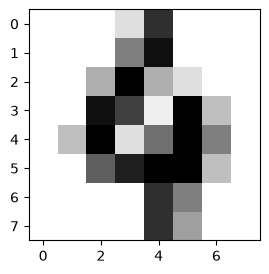

In [14]:
digits = load_digits()
X_digits, y_digits = digits.data, digits.target

# Example of a digit from the dataset
plt.figure(1, figsize=(3, 3))
plt.imshow(digits.images[100], cmap=plt.cm.gray_r, interpolation="nearest")
plt.show()

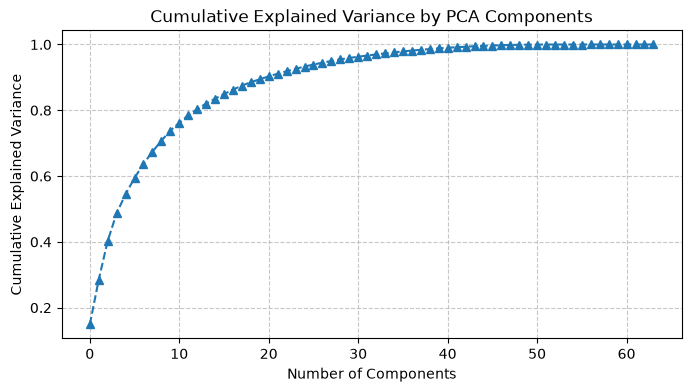

In [15]:
_, expl_var_ratio, _ = pca_via_svd(X_digits)
cum_expl_var = np.cumsum(expl_var_ratio)

plt.figure(figsize=(8, 4))
plt.plot(cum_expl_var, marker='^', linestyle='--')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

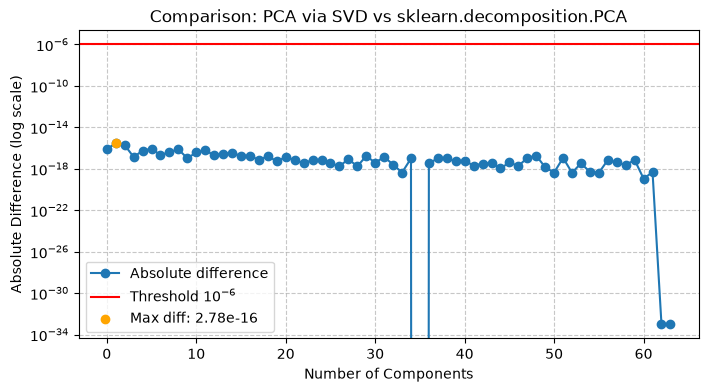

In [16]:
sklearn_pca = PCA().fit(X_digits)
pca_diff = np.abs(expl_var_ratio - sklearn_pca.explained_variance_ratio_)

max_diff_idx = np.argmax(pca_diff)
max_diff_val = pca_diff[max_diff_idx]

plt.figure(figsize=(8, 4))
plt.plot(pca_diff, marker='o', label='Absolute difference')
plt.axhline(y=10**(-6), color='red', label='Threshold $10^{-6}$')
plt.scatter(max_diff_idx, max_diff_val, color='orange', zorder=5, label=f'Max diff: {max_diff_val:.2e}')

plt.yscale('log')
plt.xlabel('Number of Components')
plt.ylabel('Absolute Difference (log scale)')
plt.title('Comparison: PCA via SVD vs sklearn.decomposition.PCA')
plt.legend(loc='best')
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

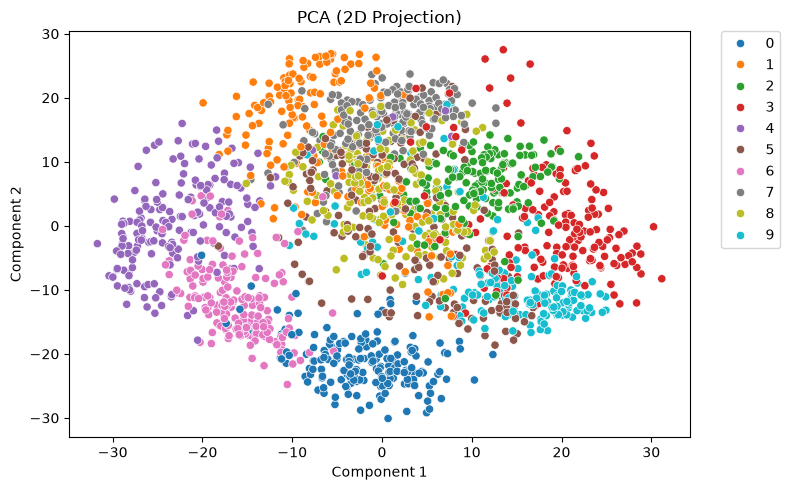

In [17]:
X_transformed_2d, _, _ = pca_via_svd(X_digits, n_components=2)

df_pca_2d = pd.DataFrame(X_transformed_2d, columns=["Component 1", "Component 2"])
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_pca_2d, 
    x="Component 1", 
    y="Component 2", 
    hue=y_digits,
    palette="tab10"
)

plt.title('PCA (2D Projection)')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.tight_layout()
plt.show()

##### 7. **[Python]** Run t-SNE and UMAP on the same features. Produce the three 2-D embeddings side by side (PCA, t-SNE, UMAP).

In [18]:
# == t-SNE ==
tsne = TSNE(n_components=2, random_state=42, perplexity=3)
X_tsne = tsne.fit_transform(X_digits)

# == UMAP ==
umap_reducer = umap.UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1)
X_umap = umap_reducer.fit_transform(X_digits)

c:\Users\ploci\OneDrive\Dokumenty\Studia\magisterka\semestr2\Analysis of Unstructured Data\AUD_labs\Problem Set 1\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


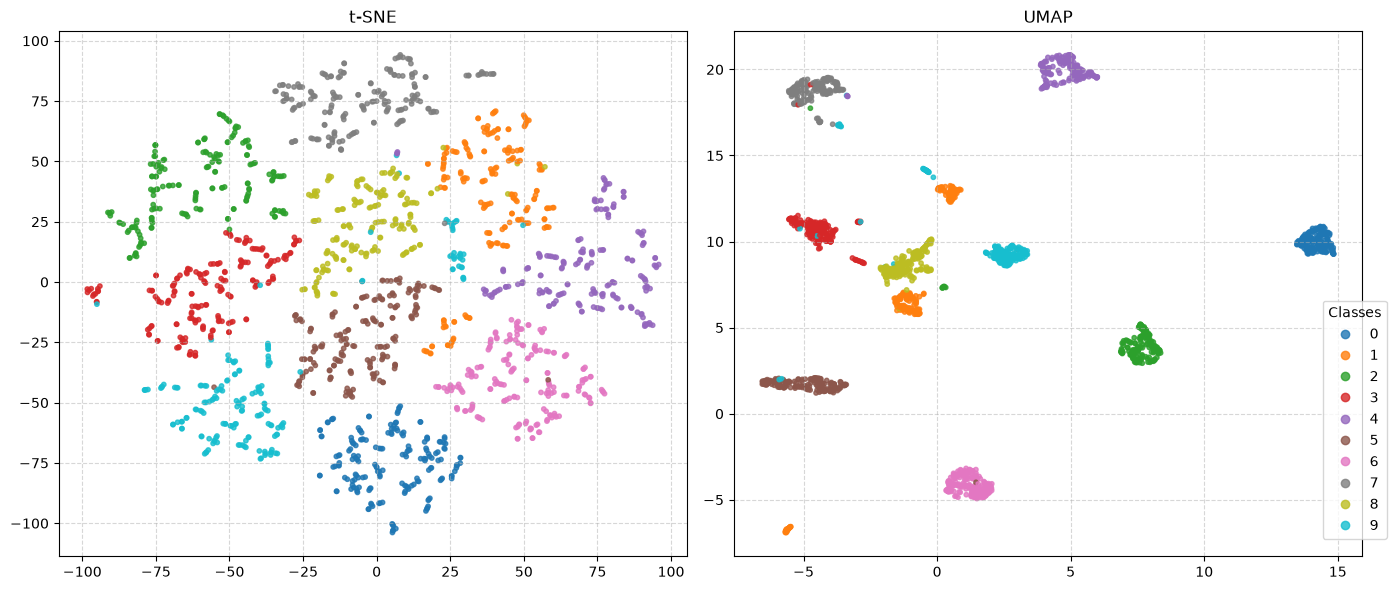

In [21]:
plt.figure(figsize=(14, 6))

# t-SNE
plt.subplot(1, 2, 1)
scatter1 = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_digits, cmap='tab10', s=10, alpha=0.8)
plt.title('t-SNE')
plt.grid(True, linestyle='--', alpha=0.5)

# UMAP
plt.subplot(1, 2, 2)
scatter2 = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y_digits, cmap='tab10', s=10, alpha=0.8)
plt.title('UMAP')
plt.grid(True, linestyle='--', alpha=0.5)

handles, labels = scatter1.legend_elements(prop="colors", alpha=0.8)
plt.legend(handles, [str(i) for i in range(10)], title="Classes", loc='best', bbox_to_anchor=(1.05, 0.5))

plt.tight_layout()
plt.show()

##### 8. **[Analysis]** Compare the three embeddings from Problem 7: which one preserves global distances, which preserves local neighbourhoods, and why can t-SNE/UMAP distances not be read as similarities? Relate your answer to Problems 1–3.